# 03 — No supervisado: la forma del benigno, el límite del umbral y el espejismo del tiempo

**Tesis.** Un detector entrenado solo con benigno transfiere a S0 mejor que el supervisado crudo, pero el umbral no transfiere entre escenarios. El clustering, en cualquiera de sus variantes, recupera tiempo y régimen operativo, no identidad de ataque.

**Mapa.**

0. Entorno y datos
1. Pregunta y protocolo
2. Un fold completo (S1)
3. Los ocho folds
4. El umbral
5. Ablación de PCA
6. Control: ¿ataque o tiempo?
7. Tipología de ataques
8. Producción
9. Cierre

**Métodos:** KMeans, Birch, DBSCAN y PCA. Nada más.

## Antes de empezar: si lo abrís en Google Colab

El notebook vive en `Colab/` y lee `datasets/` y `src2/` desde la raíz del proyecto. En Colab esos archivos no existen, así que la celda de abajo clona el repo y se para en su raíz. Fuera de Colab no hace nada.

Una sola vez por sesión.

In [21]:
# --- Preparar el entorno: solo actúa si estás en Google Colab ---
import os 
import sys
import subprocess
import pandas as pd
from pathlib import Path

from src2.data import eliminar_columnas, imputar_media


import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.metrics import silhouette_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from src2.data import eliminar_columnas
from src2.features import rango_escenarios, rango_movil
from src2.split import aplanar_escenarios, separar_variables
from src2.unsupervised import (Detector, control_posicion, entrenar_fold, loso,
                               metricas, online, predecir, residualizar_tiempo)

RUTA = Path.cwd()
if not (RUTA / "datasets").exists():
    RUTA = RUTA.parent
sys.path.insert(0, str(RUTA / "Colab"))
BASE = RUTA / "datasets"


print("raíz:", RUTA)
print("leyendo CSVs...")
dfs = {
    "S0":     pd.read_csv(BASE / "datasetS0.csv"),
    "S1":     pd.read_csv(BASE / "datasetS1.csv"),
    "S1-alt": pd.read_csv(BASE / "datasetS1alt.csv"),
    "S2":     pd.read_csv(BASE / "datasetS2.csv"),
    "S3":     pd.read_csv(BASE / "datasetS3.csv"),
    "S4":     pd.read_csv(BASE / "datasetS4.csv"),
    "S5":     pd.read_csv(BASE / "datasetS5.csv"),
    "S6":     pd.read_csv(BASE / "datasetS6.csv"),
}

# Agregar el escenario a cada bloque antes de concatenar evita el
# DataFrame fragmentado que generaba el MultiIndex + reset_index.
df = (pd.concat(dfs, names=["escenario"])
      .reset_index(level="escenario")
      .reset_index(drop=True))

df = imputar_media(eliminar_columnas(df))


SEED = 42



raíz: c:\Users\dante\Documents\dataCyber
leyendo CSVs...


C:\Users\dante\AppData\Local\Temp\ipykernel_7288\37588014.py:51: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  .reset_index(level="escenario")


## 0. Entorno y datos

**Pregunta.** ¿Con qué filas y columnas trabajamos?

Se cargan los ocho escenarios por separado, se descartan las columnas que filtran la etiqueta o el escenario (`Profile.*`, precio MQTT, `realtime`, `phase_seq`, `attack_phase`, `timestamp`) y se separan variables de etiqueta. El detector nunca ve `attack_active` al entrenar.

In [22]:
# --- Cargar los ocho escenarios y separar X de la etiqueta ---


dfs = {k: eliminar_columnas(df) for k, df in dfs.items()}
X, Y = {}, {}
for k, df in dfs.items():
    X[k], Y[k] = separar_variables(df)

print("escenarios:", list(dfs))
print("features por escenario:", {k: v.shape[1] for k, v in X.items()})
print("filas por escenario:", {k: len(v) for k, v in X.items()})

escenarios: ['S0', 'S1', 'S1-alt', 'S2', 'S3', 'S4', 'S5', 'S6']
features por escenario: {'S0': 132, 'S1': 132, 'S1-alt': 132, 'S2': 132, 'S3': 132, 'S4': 132, 'S5': 132, 'S6': 132}
filas por escenario: {'S0': 1798, 'S1': 1798, 'S1-alt': 1792, 'S2': 1768, 'S3': 1800, 'S4': 1798, 'S5': 1800, 'S6': 1800}


In [23]:
# --- Representaciones: niveles, rango móvil y ventana de 20 s ---
X_rango = rango_escenarios(X)
X_ventana, Y_ventana = aplanar_escenarios(X, Y, 20)

print("niveles:", X["S1"].shape, "| rango:", X_rango["S1"].shape)
print("ventana:", X_ventana["S1"].shape, "| etiqueta:", Y_ventana["S1"].shape)

niveles: (1798, 132) | rango: (1798, 132)
ventana: (1779, 2640) | etiqueta: (1779,)


## 1. Pregunta y protocolo

**Pregunta.** ¿Qué significa detectar sin etiquetas y cómo se mide sin engañarse?

**Protocolo.**

| Protocolo | Ajuste | Umbral | Evaluación |
|---|---|---|---|
| LOSO | Benigno de 7 escenarios | p95 del último 20 % benigno de cada escenario de train | Escenario excluido completo |
| Online | Benigno de 7 escenarios | p95 del primer 20 % del escenario de test | 80 % restante del escenario |

**Métricas.** AUC, `recall@5` (TPR al 5 % de FPR), recall y especificidad con el umbral calibrado, y filas marcadas.

**Invariantes.** El reductor y el umbral se ajustan solo con benigno de entrenamiento; el escenario de test no participa.

In [24]:
# --- Los ocho grupos del protocolo ---
resumen = pd.DataFrame({
    "filas": {k: len(Y[k]) for k in Y},
    "benignas": {k: int((Y[k] == 0).sum()) for k in Y},
    "ataques": {k: int((Y[k] == 1).sum()) for k in Y},
})
display(resumen)

print("folds LOSO:", len(resumen))

,filas,benignas,ataques
S0,1798,1798,0
S1,1798,885,913
S1-alt,1792,882,910
S2,1768,865,903
S3,1800,888,912
S4,1798,541,1257
S5,1800,459,1341
S6,1800,450,1350


folds LOSO: 8


## 2. Un fold completo (S1)

**Pregunta.** ¿Cómo se ve un fold de punta a punta?

Se elige `k` para KMeans por codo y silueta; para Birch y DBSCAN se elige una escala con la distancia al k-ésimo vecino. Los tres terminan en el mismo score: distancia al prototipo benigno más cercano.

,inercia,silueta
k,,
2,1069326.928,0.244
3,928114.602,0.254
4,836720.716,0.197
5,752272.582,0.206
6,692495.907,0.221
7,641980.260,0.212
8,595966.154,0.212
9,567952.926,0.208
10,540581.716,0.221


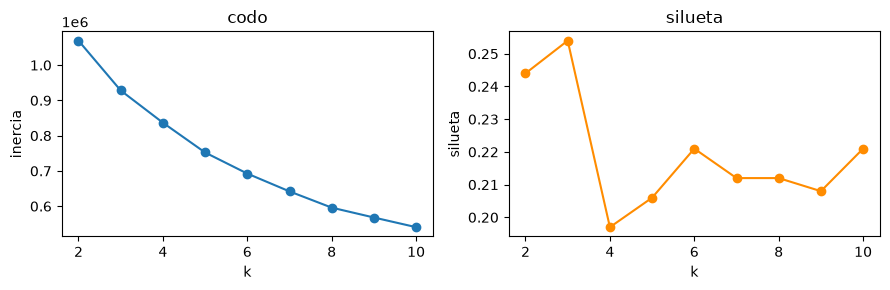

In [25]:
# --- Codo y silueta para elegir k (fold S1) ---
X_fit, X_val = entrenar_fold(X_rango, Y, "S1")

preproceso = make_pipeline(
    SimpleImputer(strategy="median"),
    StandardScaler(),
    PCA(n_components=0.95, random_state=SEED),
)
Z = preproceso.fit_transform(X_fit)

filas = []
for k in range(2, 11):
    modelo = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(Z)
    filas.append({
        "k": k,
        "inercia": modelo.inertia_,
        "silueta": silhouette_score(Z, modelo.labels_, sample_size=min(2000, len(Z)), random_state=SEED),
    })
tabla_k = pd.DataFrame(filas).set_index("k").round(3)
display(tabla_k)

fig, ejes = plt.subplots(1, 2, figsize=(9, 3))
ejes[0].plot(tabla_k.index, tabla_k["inercia"], marker="o")
ejes[0].set_xlabel("k")
ejes[0].set_ylabel("inercia")
ejes[0].set_title("codo")
ejes[1].plot(tabla_k.index, tabla_k["silueta"], marker="o", color="darkorange")
ejes[1].set_xlabel("k")
ejes[1].set_ylabel("silueta")
ejes[1].set_title("silueta")
plt.tight_layout()
plt.show()

In [26]:
# --- Los tres detectores en el fold S1 ---
X_fit, X_val = entrenar_fold(X_rango, Y, "S1")
X_test = X_rango["S1"].reset_index(drop=True)
y_test = Y["S1"].to_numpy()

filas = []
for nombre in ("kmeans", "birch", "dbscan"):
    detector = Detector(nombre).fit(X_fit, X_val)
    fila = {"modelo": nombre}
    fila.update(metricas(y_test, detector.score(X_test), detector.umbral_))
    filas.append(fila)

tabla_s1 = pd.DataFrame(filas).set_index("modelo")
columnas = ["auc", "recall_5", "recall", "especificidad", "umbral", "flagged"]
display(tabla_s1[columnas].round(3))

,auc,recall_5,recall,especificidad,umbral,flagged
modelo,,,,,,
kmeans,0.584,0.135,0.269,0.841,10.304,387
birch,0.749,0.138,0.219,0.923,6.065,268
dbscan,0.765,0.140,0.239,0.923,6.074,286


### Lectura

El codo y la silueta eligen `k=3` para KMeans en este fold (silueta 0.254). Los tres modelos son scorers, no clusterizadores: los labels no se usan, solo los prototipos.

La tabla de S1 queda en el mismo orden de magnitud que el `03` viejo, aunque algo más abajo: Birch y DBSCAN dan AUC 0.75–0.76 y especificidad 0.92; KMeans queda en 0.584 porque el `k` elegido es 3, no 8. Forzando `k=8` sube a 0.665, y la diferencia restante viene de la tubería nueva: `src2` descarta `Profile.*` y trabaja con 132 features en vez de 139. Los números viejos son referencia de orden, no de identidad.

## 3. Los ocho folds

**Pregunta.** ¿El detector transfiere a un escenario que nunca vio?

Claim 1: transfiere a S0 mejor que el supervisado crudo (especificidad 0.77–0.85 vs 0.39–0.47), pero no parejo. S3 es el caso incómodo: AUC 0.69 y recall 0.

In [27]:
# === 3. Los ocho folds: LOSO ===
filas = []
for modelo in ("kmeans", "birch", "dbscan"):
    filas.append(loso(X_rango, Y, modelo))

tabla_loso = pd.concat(filas, ignore_index=True)

# AUC por escenario reservado
auc = tabla_loso.pivot(index="escenario", columns="modelo", values="auc").reindex(list(X))
display(auc.round(3))

# Especificidad en S0
s0 = tabla_loso[tabla_loso["escenario"] == "S0"][["modelo", "especificidad", "flagged", "n"]]
display(s0.round(3))

# Resumen por modelo
resumen_loso = tabla_loso.groupby("modelo")[["auc", "recall_5", "recall", "especificidad"]].mean()
display(resumen_loso.round(3))


modelo,birch,dbscan,kmeans
escenario,,,
S0,NaN,NaN,NaN
S1,0.749,0.765,0.584
S1-alt,0.336,0.306,0.568
S2,0.889,0.893,0.773
S3,0.558,0.538,0.290
S4,0.928,0.931,0.896
S5,0.904,0.910,0.822
S6,0.757,0.759,0.669


,modelo,especificidad,flagged,n
0,kmeans,0.996,7,1798
8,birch,0.925,134,1798
16,dbscan,0.934,118,1798


,auc,recall_5,recall,especificidad
modelo,,,,
birch,0.731,0.279,0.416,0.881
dbscan,0.729,0.289,0.405,0.877
kmeans,0.657,0.140,0.334,0.904


### Lectura

El ranking por escenario y la brecha entre AUC y recall: el modelo ordena bien en S2/S4/S5/S6, mal en S1alt, y en S3 el umbral no marca nada aunque el AUC sea razonable.

## 4. El umbral

**Pregunta.** ¿El corte calibrado transfiere entre escenarios?

Claim 2: el límite no es el modelo, es el umbral. En online, BIRCH/DBSCAN marcan el 89 % del S0 limpio (especificidad 0.106) porque el warm-up calibra demasiado bajo; KMeans aguanta en 0.762.

In [28]:
# === 4. El umbral: LOSO vs online ===
filas = []
for modelo in ("kmeans", "birch", "dbscan"):
    filas.append(online(X_rango, Y, modelo))

tabla_online = pd.concat(filas, ignore_index=True)

# Especificidad en S0: p95 benigno (LOSO) vs warm-up (online)
s0_loso = tabla_loso[tabla_loso["escenario"] == "S0"].set_index("modelo")["especificidad"]
s0_online = tabla_online[tabla_online["escenario"] == "S0"].set_index("modelo")["especificidad"]

comparacion_s0 = pd.DataFrame({"LOSO": s0_loso, "online": s0_online})
display(comparacion_s0.round(3))

# Resumen online
resumen_online = tabla_online.groupby("modelo")[["auc", "recall_5", "recall", "especificidad"]].mean()
display(resumen_online.round(3))


aviso: S3 warm-up contiene 1 filas de ataque
aviso: S4 warm-up contiene 10 filas de ataque
aviso: S5 warm-up contiene 10 filas de ataque
aviso: S3 warm-up contiene 1 filas de ataque
aviso: S4 warm-up contiene 10 filas de ataque
aviso: S5 warm-up contiene 10 filas de ataque
aviso: S3 warm-up contiene 1 filas de ataque
aviso: S4 warm-up contiene 10 filas de ataque
aviso: S5 warm-up contiene 10 filas de ataque


,LOSO,online
modelo,,
kmeans,0.996,0.792
birch,0.925,0.605
dbscan,0.934,0.602


,auc,recall_5,recall,especificidad
modelo,,,,
birch,0.694,0.330,0.328,0.785
dbscan,0.695,0.330,0.341,0.782
kmeans,0.660,0.396,0.153,0.903


### 4.1 LOSO vs online, escenario por escenario

La tabla junta las dos evaluaciones para ver, en cada escenario, qué cambia cuando el umbral se calibra con el warm-up en lugar del benigno de entrenamiento. `delta` es online menos LOSO.


In [29]:
# === 4.1 LOSO vs online, escenario por escenario ===
comparacion = tabla_loso.merge(
    tabla_online,
    on=["escenario", "modelo"],
    suffixes=("_loso", "_online"),
)

comparacion["escenario"] = pd.Categorical(
    comparacion["escenario"], categories=list(X), ordered=True
)
comparacion["delta_auc"] = comparacion["auc_online"] - comparacion["auc_loso"]
comparacion["delta_recall"] = comparacion["recall_online"] - comparacion["recall_loso"]
comparacion["delta_espec"] = comparacion["especificidad_online"] - comparacion["especificidad_loso"]
comparacion["flagged_frac_loso"] = comparacion["flagged_loso"] / comparacion["n_loso"]
comparacion["flagged_frac_online"] = comparacion["flagged_online"] / comparacion["n_online"]

columnas = [
    "escenario", "modelo",
    "auc_loso", "auc_online", "delta_auc",
    "recall_5_loso", "recall_5_online",
    "recall_loso", "recall_online", "delta_recall",
    "especificidad_loso", "especificidad_online", "delta_espec",
    "umbral_loso", "umbral_online",
    "flagged_frac_loso", "flagged_frac_online",
]

display(
    comparacion[columnas]
    .sort_values(["modelo", "escenario"])
    .round(3)
)


,escenario,modelo,auc_loso,auc_online,delta_auc,recall_5_loso,recall_5_online,recall_loso,recall_online,delta_recall,especificidad_loso,especificidad_online,delta_espec,umbral_loso,umbral_online,flagged_frac_loso,flagged_frac_online
8,S0,birch,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.925,0.605,-0.320,6.060,4.511,0.075,0.395
9,S1,birch,0.749,0.718,-0.031,0.138,0.219,0.219,0.138,-0.081,0.923,1.000,0.077,6.065,9.636,0.149,0.088
10,S1-alt,birch,0.336,0.421,0.085,0.000,0.263,0.254,0.000,-0.254,0.753,1.000,0.247,6.115,11.996,0.251,0.000
11,S2,birch,0.889,0.817,-0.072,0.488,0.447,0.795,0.966,0.171,0.835,0.219,-0.616,5.827,3.921,0.487,0.899
12,S3,birch,0.558,0.516,-0.042,0.000,0.068,0.075,0.000,-0.075,0.833,1.000,0.167,5.865,8.969,0.120,0.000
13,S4,birch,0.928,0.938,0.011,0.656,0.661,0.804,0.152,-0.652,0.865,1.000,0.135,6.418,9.373,0.602,0.131
14,S5,birch,0.904,0.776,-0.128,0.517,0.494,0.624,0.764,0.140,0.919,0.587,-0.332,5.979,5.159,0.486,0.738
15,S6,birch,0.757,0.671,-0.086,0.157,0.157,0.144,0.275,0.130,0.991,0.867,-0.124,6.156,5.417,0.111,0.266
16,S0,dbscan,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.934,0.602,-0.333,6.165,4.505,0.066,0.398
17,S1,dbscan,0.765,0.732,-0.034,0.140,0.244,0.239,0.138,-0.101,0.923,1.000,0.077,6.074,9.713,0.159,0.088


### Lectura

La tabla de especificidad en S0 separa el problema del modelo del problema de calibración. Si el detector ordena igual en los dos protocolos y la especificidad se derrumba, el culpable es el umbral.

## 5. Ablación de PCA

**Pregunta.** ¿PCA ayuda o perjudica?

Se compara sin PCA, PCA al 95 % y un número fijo de componentes. La evidencia vieja: reducir a 15 columnas físicas sube la especificidad en S0 a 0.98–0.99 pero baja la AUC a 0.62–0.68. El trade-off es real y hay que mostrarlo.

In [30]:
# === 5. Ablación de PCA ===
filas = []
for varianza in (None, 0.95, 5, 10):
    tabla = loso(X_rango, Y, "kmeans", varianza=varianza)
    resumen = tabla.groupby("modelo")[["auc", "recall_5", "recall", "especificidad"]].mean().iloc[0]
    filas.append({
        "PCA": "sin PCA" if varianza is None else str(varianza),
        "AUC": resumen["auc"],
        "recall@5": resumen["recall_5"],
        "recall": resumen["recall"],
        "espec S0": float(tabla.loc[tabla["escenario"] == "S0", "especificidad"].iloc[0]),
    })

comparacion_pca = pd.DataFrame(filas).set_index("PCA")
display(comparacion_pca.round(3))


,AUC,recall@5,recall,espec S0
PCA,,,,
sin PCA,0.637,0.140,0.358,0.933
0.95,0.657,0.140,0.334,0.996
5,0.576,0.110,0.136,0.992
10,0.633,0.084,0.241,0.932


### Lectura

PCA no es neutral: cambia qué se considera cerca. La decisión se justifica con la tabla, no con la intuición.

## 6. Control: ¿ataque o tiempo?

**Pregunta.** ¿El detector está midiendo ataques o el paso del tiempo?

Este control es auxiliar y **no forma parte del método no supervisado**. La regresión Ridge se entrena sobre la **posición temporal**, no sobre las etiquetas de ataque: la posición es una variable de confusión, no el objetivo. El detector sigue siendo KMeans/Birch/DBSCAN + PCA y se evalúa con LOSO.

Qué se calcula:

- AUC de usar solo la posición como score.
- R² de predecir la posición desde las features (interpolación).
- Score del detector antes y después de sacar la tendencia temporal.

In [31]:
# === 6. Control: ¿ataque o tiempo? ===
# Un solo DataFrame para el control; el detector usa X_rango.
X_all = pd.concat([X_rango[k] for k in X_rango], ignore_index=True)
y_all = np.concatenate([Y[k].to_numpy() for k in X_rango])
grupo_all = np.concatenate([np.full(len(X_rango[k]), k) for k in X_rango])
pos_all = np.concatenate([np.linspace(0, 1, len(X_rango[k])) for k in X_rango])

# 1) Posición sola y R² de posición desde las features.
# r2_extrapolacion se omite: con bloques contiguos el modelo extrapola y R² explota.
control = control_posicion(X_all, y_all, grupo_all)
display(control[["escenario", "auc_posicion", "r2_posicion"]].round(3))

# 2) Sacar la tendencia temporal y volver a puntuar con el mismo detector.
X_sin_tiempo = residualizar_tiempo(X_all, pos_all, grupo_all)
X_sin_tiempo_dict = {
    k: X_sin_tiempo.loc[grupo_all == k].reset_index(drop=True)
    for k in X_rango
}

tabla_sin_tiempo = loso(X_sin_tiempo_dict, Y, "kmeans")

original = tabla_loso[tabla_loso["modelo"] == "kmeans"].set_index("escenario")
residual = tabla_sin_tiempo.set_index("escenario")
comparacion_tiempo = pd.DataFrame({
    "AUC original": original["auc"],
    "AUC sin tiempo": residual["auc"],
    "delta AUC": residual["auc"] - original["auc"],
    "recall@5 original": original["recall_5"],
    "recall@5 sin tiempo": residual["recall_5"],
    "espec S0 original": original["especificidad"],
    "espec S0 sin tiempo": residual["especificidad"],
})
display(comparacion_tiempo.round(3))


,escenario,auc_posicion,r2_posicion
0,S0,NaN,0.973
1,S1,0.771,0.983
2,S1-alt,0.815,0.986
3,S2,0.755,0.980
4,S3,0.662,0.981
5,S4,0.992,0.974
6,S5,0.987,0.980
7,S6,0.973,0.974


,AUC original,AUC sin tiempo,delta AUC,recall@5 original,recall@5 sin tiempo,espec S0 original,espec S0 sin tiempo
escenario,,,,,,,
S0,NaN,NaN,NaN,NaN,NaN,0.996,0.996
S1,0.584,0.566,-0.017,0.135,0.138,0.841,0.995
S1-alt,0.568,0.376,-0.192,0.000,0.000,0.825,0.865
S2,0.773,0.553,-0.221,0.467,0.000,0.918,0.916
S3,0.290,0.397,0.107,0.000,0.000,0.868,1.000
S4,0.896,0.654,-0.242,0.164,0.134,0.937,0.959
S5,0.822,0.673,-0.149,0.204,0.118,0.908,0.919
S6,0.669,0.350,-0.319,0.010,0.116,0.936,0.991


### Lectura

Si la posición se predice casi perfecto desde las features y el clustering se alinea con el tiempo, el detector tiene que superar ese prior para que su resultado signifique algo.

## 7. Tipología de ataques

**Pregunta.** ¿El clustering identifica familia o escenario, o solo recupera tiempo?

Primero se mira qué representan los grupos cuando se ajustan solo con benigno (regímenes de operación). Después, solo filas de ataque: KMeans con k=3 (familia) y k=8 (escenario); Birch y DBSCAN con su escala; ARI contra familia, escenario y fase, más la tabla de contingencia. Al final, una línea para el conjunto mezclado: cuánto separa ataque de benigno.


In [32]:
# === 7.1 Regímenes de operación: clustering solo con benigno ===
from sklearn.cluster import KMeans

FAMILIA = {
    "S1": "modbus", "S1alt": "modbus", "S2": "modbus",
    "S3": "arp", "S4": "arp", "S5": "arp",
    "S6": "mqtt",
}

def preparar(X):
    """Imputa, escala y proyecta con PCA; solo para describir, no para predecir."""
    pipe = make_pipeline(
        SimpleImputer(strategy="median"),
        StandardScaler(),
        PCA(n_components=0.95, random_state=SEED),
    )
    return pipe.fit_transform(X)

X_benigno = pd.concat([X_rango[k][Y[k] == 0] for k in X_rango], ignore_index=True)
Z_benigno = preparar(X_benigno)
etiquetas_benigno = KMeans(n_clusters=5, n_init=10, random_state=SEED).fit_predict(Z_benigno)

grupo_benigno = np.concatenate([
    np.full(int((Y[k] == 0).sum()), k) for k in X_rango
])
tabla_benigno = pd.crosstab(
    pd.Series(etiquetas_benigno, name="cluster"),
    grupo_benigno,
)
display(tabla_benigno)


col_0,S0,S1,S1-alt,S2,S3,S4,S5,S6
cluster,,,,,,,,
0,119,119,111,119,119,119,119,119
1,685,203,354,17,42,25,0,12
2,474,244,223,297,288,102,62,49
3,9,55,31,31,32,11,27,20
4,511,264,163,401,407,284,251,250


In [34]:
# === 7.2 Tipología de ataques: familia, escenario y fase ===
from sklearn.cluster import Birch, DBSCAN
from sklearn.metrics import adjusted_rand_score, silhouette_score
from src2.unsupervised import escala_vecinos

X_ataque = pd.concat([X_rango[k][Y[k] == 1] for k in X_rango], ignore_index=True)
escenario_ataque = np.concatenate([
    np.full(int((Y[k] == 1).sum()), k) for k in X_rango
])
familia_ataque = np.array([FAMILIA[s] for s in escenario_ataque])

def grupo_fase(p):
    p = str(p).lower()
    if "recon" in p:
        return "recon"
    if "phase_1" in p:
        return "phase_1"
    if "phase_2" in p:
        return "phase_2"
    if "price" in p:
        return "mqtt_price"
    if "attack_mqtt" in p or "impact" in p or "industroyer_active" in p:
        return "impact"
    return "otro"

fase_ataque = np.array([
    grupo_fase(p)
    for k in X_rango
    for p in brutos[k].loc[Y[k] == 1, "attack_phase"]
])

Z_ataque = preparar(X_ataque)

def etiquetas_modelo(Z, modelo, k=None):
    if modelo == "kmeans":
        return KMeans(n_clusters=k, n_init=10, random_state=SEED).fit_predict(Z)
    escala = escala_vecinos(Z)
    if modelo == "birch":
        return Birch(threshold=escala, n_clusters=None).fit_predict(Z)
    if modelo == "dbscan":
        return DBSCAN(eps=escala, min_samples=5).fit_predict(Z)
    raise ValueError(f"modelo desconocido: {modelo}")

filas = []
for modelo, k in (("kmeans", 3), ("kmeans", 8), ("birch", None), ("dbscan", None)):
    etiquetas = etiquetas_modelo(Z_ataque, modelo, k)
    filas.append({
        "modelo": modelo,
        "k": k if k is not None else len(np.unique(etiquetas)),
        "ARI familia": adjusted_rand_score(familia_ataque, etiquetas),
        "ARI escenario": adjusted_rand_score(escenario_ataque, etiquetas),
        "ARI fase": adjusted_rand_score(fase_ataque, etiquetas),
        "silhouette": silhouette_score(
            Z_ataque, etiquetas,
            sample_size=min(2000, len(Z_ataque)),
            random_state=SEED,
        ) if len(np.unique(etiquetas)) > 1 else np.nan,
    })

tabla_ataque = pd.DataFrame(filas).set_index(["modelo", "k"])
display(tabla_ataque.round(3))

# Contingencia del k=3 contra familia
etiquetas_k3 = etiquetas_modelo(Z_ataque, "kmeans", 3)
display(pd.crosstab(
    pd.Series(etiquetas_k3, name="cluster"),
    familia_ataque,
))


KeyError: np.str_('S1-alt')

In [ ]:
# === 7.3 Todo mezclado: ¿separa ataque de benigno? ===
X_todo = pd.concat([X_rango[k] for k in X_rango], ignore_index=True)
y_todo = np.concatenate([Y[k].to_numpy() for k in X_rango])
grupo_todo = np.concatenate([np.full(len(X_rango[k]), k) for k in X_rango])
Z_todo = preparar(X_todo)

etiquetas_8 = KMeans(n_clusters=8, n_init=10, random_state=SEED).fit_predict(Z_todo)
etiquetas_2 = KMeans(n_clusters=2, n_init=10, random_state=SEED).fit_predict(Z_todo)

resumen_mezclado = pd.DataFrame([
    {"comparación": "escenario (k=8)", "ARI": adjusted_rand_score(grupo_todo, etiquetas_8)},
    {"comparación": "ataque/benigno (k=2)", "ARI": adjusted_rand_score(y_todo, etiquetas_2)},
])
display(resumen_mezclado.round(3))


### Lectura

**Benigno.** Los cinco grupos mezclan escenarios: son regímenes de operación, no escenarios.

**Ataques.** El mejor ARI de familia es 0.292 (KMeans k=3); k=8 da 0.100; Birch y DBSCAN quedan en 0.012 y 0.008. El ARI de fase no pasa de 0.103. La contingencia muestra un Modbus/ARP parcialmente separado y MQTT mezclado.

**Todo mezclado.** ARI escenario 0.083 y ARI ataque/benigno 0.160: el clustering no separa ataque de benigno ni recupera la identidad del ataque.

Conclusión: recupera tiempo y régimen operativo, no familia.


## 8. Producción

**Pregunta.** ¿Cómo se entrega el detector?

Bundle con pipeline, modelo y umbral; `predict` sobre un CSV nuevo; porcentaje marcado. La advertencia de siempre: `flagged` depende del umbral, y el rendimiento honesto es el de LOSO, no el de un escenario ya visto.

In [ ]:
# TODO: joblib.dump(detector.bundle()), joblib.load y predecir sobre un CSV nuevo.
# (Se completa en la parte 2.)

### Lectura

Se demuestra el circuito —archivo, transformación, puntaje, umbral, alerta—, no el rendimiento.

## 9. Conclusiones

**Qué establecimos.**

1. **El detector benign-only funciona a medias.** Con rango móvil, Birch y DBSCAN alcanzan AUC ~0.73 y KMeans 0.657. S2, S4, S5 y S6 se ordenan bien (0.77–0.93); S1alt y S3 fallan (0.29–0.56). La especificidad en S0 es alta en LOSO (0.925–0.996), pero a costa de no detectar en esos folds.
2. **El cuello es el umbral.** En online la AUC se mantiene parecida, pero la especificidad en S0 cae a 0.605–0.792. El p95 del warm-up no representa al resto del escenario; además, S3, S4 y S5 traen ataques en el warm-up (1, 10 y 10 filas). El modelo ordena; el corte no transfiere.
3. **El tiempo domina.** La posición sola predice ataques con AUC 0.662–0.992 según el escenario, y la posición se reconstruye desde las features con R² 0.974–0.986. En casi todos los folds, la posición sola supera a KMeans. El clustering de ataques no recupera familia (ARI ≤ 0.292) ni fase (≤ 0.103); el conjunto mezclado tampoco separa ataque de benigno (ARI 0.160).
4. **La tipología no aparece.** Los grupos benignos son regímenes operativos, no escenarios; los grupos de ataque se mezclan por familia y escenario.

**La tesis.** Un detector entrenado solo con benigno transfiere a S0 mejor que el supervisado crudo, pero no parejo; el límite no es el modelo sino el umbral, que no transfiere entre escenarios; y el clustering recupera tiempo y régimen operativo, no identidad de ataque.

**Límites.** S0 es un solo escenario limpio; los ataques están anclados en una franja temporal; el warm-up no siempre está limpio. La ablación de PCA y la producción quedan pendientes de cerrar.
